## Computational Physics -- Problem Set 9
##### _Theodore Landa_

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('svg')

### Problem 1.

Plots! I plotted $\rho$, and then I plotted $\phi$.

In [6]:
xs101 = np.arange(101) / 100
xsgrid101, ysgrid101 = np.meshgrid(xs101, xs101)

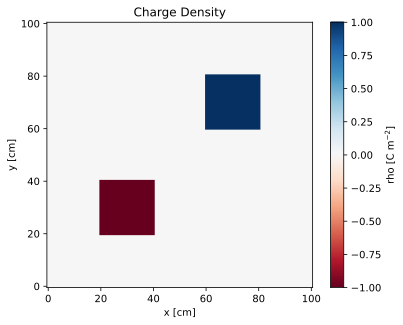

In [7]:
rho = np.zeros(xsgrid101.shape)
rhomaskp = ((xsgrid101 >= 0.6) & (xsgrid101 <= 0.8)) & ((ysgrid101 >= 0.6) & (ysgrid101 <= 0.8))
rho[rhomaskp] = 1
rhomaskn = ((xsgrid101 >= 0.2) & (xsgrid101 <= 0.4)) & ((ysgrid101 >= 0.2) & (ysgrid101 <= 0.4))
rho[rhomaskn] = -1
plt.imshow(rho, "RdBu", origin="lower")
plt.title("Charge Density")
plt.xlabel("x [cm]")
plt.ylabel("y [cm]")
plt.colorbar(label="rho [C m$^{-2}$]")
plt.show()

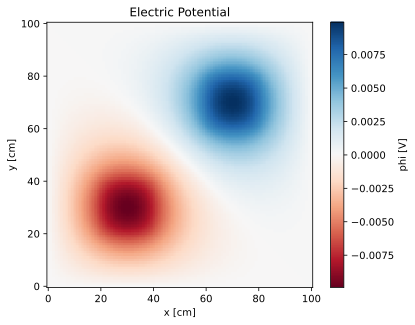

In [8]:
phi = np.zeros(xsgrid101.shape)
phiprime = np.ones(xsgrid101.shape)
op1 = np.eye(101**2, k=1) + np.eye(101**2, k=-1) + np.eye(101**2, k=101) + np.eye(101**2, k=-101)
while (np.any(np.abs(phi - phiprime) > 1e-6)):
    phiprime = phi
    phi = 0.25 * ((op1 @ np.ravel(phiprime)).reshape(101, 101) + 0.01**2 * rho)
    phi[:,0] = 0
    phi[:,100] = 0
    phi[0,:] = 0
    phi[100,:] = 0
plt.imshow(phi, "RdBu", origin="lower")
plt.xlabel("x [cm]")
plt.ylabel("y [cm]")
plt.title("Electric Potential")
plt.colorbar(label="phi [V]")
plt.show()

### Problem 2.

_(a)_ We compute the matrix elements $L_{ii}$ to be `-3.6905989232414975` and the matrix elements $L_{ij}$ to be `0.2679491924311227`, `0.577350269189626`, and `1.` for the three anisotropic directions. This is a weird deliverable but I don't want to lose points. Actually it was useful to write this because I found a bug...

_(b)_ Code

_(c)_ Plot!

_(b)_ Plot!

In [2]:
def get_trap_coords(M):
    ones_trap = np.flip(np.tri(M+1, 2*M+1, k=M), 0)
    ones_trap[ones_trap==0] = np.nan
    trap_y_ind, trap_x_ind = ones_trap * np.indices((M+1, 2*M+1))
    trap_y = trap_y_ind * (np.sqrt(3) / (np.sqrt(3) + 1))
    trap_x = trap_y + trap_x_ind
    return trap_x, trap_y

In [3]:
def cot(theta):
    return 1 / np.tan(theta * np.pi / 180)

L_ii = -2 * (cot(75) + 1 + cot(60))
print(L_ii)
print(cot(75))
print(cot(60))

-3.6905989232414975
0.2679491924311227
0.577350269189626


In [4]:
def make_op2(M):
    size = (M + 1) * (2 * M + 1)
    return (-1 / L_ii) * (cot(75) * np.eye(size, k=1) + cot(75) * np.eye(size, k=-1) + \
    cot(60) * np.eye(size, k=2*M+1) + cot(60) * np.eye(size, k=-2*M-1) + \
    np.eye(size, k=2*M) + np.eye(size, k=-2*M))

In [5]:
def solve_trap(M, tol):
    phi = np.zeros((M+1, 2*M+1))
    phiprime = np.ones((M+1, 2*M+1))
    edge = np.flip(np.tri(M+1, 2*M+1, k=M-1), 0)
    op2 = make_op2(M)
    while (np.any(np.abs(phi - phiprime) > tol)):
        phiprime = phi
        phi = (op2 @ np.ravel(phiprime)).reshape((M+1, 2*M+1))
        phi[0,:] = 0*phi[0,:] - 1
        phi[M,:] = 0*phi[M,:] + 1
        phi[:,0] = 0
        phi = phi * edge
    return phi

In [6]:
phi_4 = solve_trap(4, 1e-6)
trap_x_4, trap_y_4 = get_trap_coords(4)

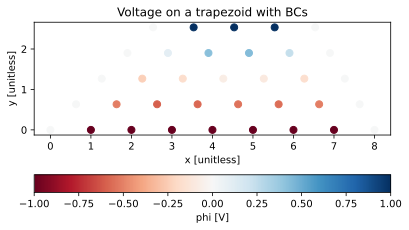

In [21]:
scatter4 = plt.scatter(trap_x_4, trap_y_4, c=phi_4, cmap="RdBu", s=50)
plt.title("Voltage on a trapezoid with BCs")
plt.xlabel("x [unitless]")
plt.ylabel("y [unitless]")
cbar4 = plt.colorbar(scatter4, orientation="horizontal")
cbar4.set_label("phi [V]")
plt.gca().set_aspect(1.)
plt.show()

In [30]:
phi_100 = solve_trap(100, 1e-6)
trap_x_100, trap_y_100 = get_trap_coords(100)

In [31]:
scatter100 = plt.scatter(trap_x_100, trap_y_100, c=phi_100, cmap="RdBu", s=1)
plt.title("Voltage on a trapezoid with BCs")
plt.xlabel("x [unitless]")
plt.ylabel("y [unitless]")
cbar100 = plt.colorbar(scatter100, orientation="horizontal")
cbar100.set_label("phi [V]")
plt.gca().set_aspect(1.)
plt.show()

### Problem 3.

_(a)_

### Credits.

Numpy, matplotlib documentation. So many useful numpy functions.